# Resultados del proyecto (sin llave de API)

Reproduce el EDA básico, la Parte 1 (Naive Bayes propio), la evaluación con origen móvil, la verificación contra scikit-learn, la evaluación del RAG y el resumen de la evaluación del agente.

In [1]:
import sys, json, pathlib, warnings
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / 'src')); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import modelo as nb

## 1. Datos (SIATA, PM2.5 diario por estación)

16 estaciones | 5728 días-estación | 2023-07-31 a 2024-07-30
{'Aceptable': 4520, 'Buena': 1021, 'Dañina+': 187}


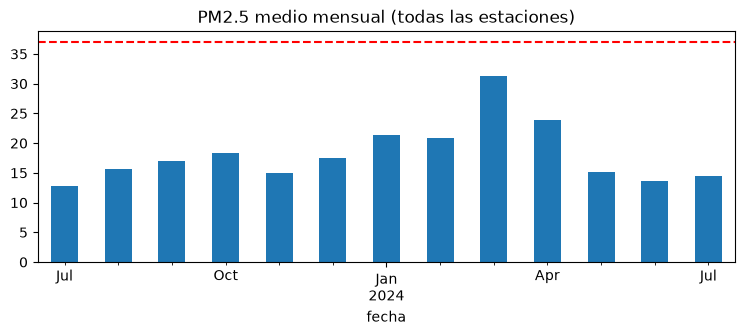

In [2]:
df = nb.cargar_datos()
print(df.estacion.nunique(), 'estaciones |', len(df), 'días-estación |', df.fecha.min().date(), 'a', df.fecha.max().date())
cat = pd.Series(np.array(['Buena','Aceptable','Dañina+'])[nb.categorizar(df.pm25).astype(int)])
print(cat.value_counts().to_dict())
m = df.groupby(df.fecha.dt.to_period('M')).pm25.mean()
ax = m.plot(kind='bar', figsize=(9,3), title='PM2.5 medio mensual (todas las estaciones)'); ax.axhline(37, color='r', ls='--'); plt.show()

## 2. Parte 1: partición temporal única (resultado original del equipo)

In [3]:
t = nb.construir_dataset(df)
train, test, corte = nb.split_temporal(t)
print('Prueba desde', corte.date(), '| clases en prueba:', nb.conteo(test))
cols = nb.CONJUNTOS['A_basico']; modelo = nb.entrenar(train, cols)
for nombre, pred in [('Naive Bayes A_basico', modelo.predict(test[cols].values)), ('Persistencia', test.categoria_hoy.values)]:
    m = nb.metricas(test.y.values, pred); print(f"{nombre:22s} acc={m['accuracy']:.3f}  F1 macro={m['f1_macro']:.3f}")

Prueba desde 2024-04-30 | clases en prueba: Buena=480, Aceptable=905, Dañina+=0
Naive Bayes A_basico   acc=0.737  F1 macro=0.693
Persistencia           acc=0.746  F1 macro=0.719


## 3. Verificación de corrección y validación con origen móvil (enero–julio 2024)
La partición única no tiene días *Dañina+* en la prueba; el origen móvil sí incluye la temporada crítica de 2024.

In [4]:
import evaluacion_temporal as et
print('Verificación vs sklearn CategoricalNB:', et.verificar_con_sklearn(t))
P = et.origen_movil(t); y = P.y.astype(int).values
filas = []
for nombre, col in [('Naive Bayes A_basico','pred_A_basico'), ('Persistencia','pred_persistencia'), ('Clase mayoritaria','pred_mayoritaria')]:
    m = nb.metricas(y, P[col].astype(int).values)
    filas.append({'modelo': nombre, 'exactitud': m['accuracy'], 'F1 macro': m['f1_macro'], 'recall Dañina+': et.recall_danina(y, P[col].astype(int).values)})
pd.DataFrame(filas).round(3)

Verificación vs sklearn CategoricalNB: {'acuerdo_prediccion': 1.0, 'max_diferencia_probabilidad': 9.43689570931383e-16, 'n': 1385}


,modelo,exactitud,F1 macro,recall Dañina+
0,Naive Bayes A_basico,0.815,0.666,0.489
1,Persistencia,0.811,0.692,0.610
2,Clase mayoritaria,0.768,0.290,0.000


In [5]:
print(json.dumps(et.bootstrap(P, 'pred_A_basico', 'pred_persistencia', n=1000), indent=1))

{
 "accuracy": {
  "media": 0.003791251425850842,
  "ic95": [
   -0.00799766229563667,
   0.014167688502587416
  ]
 },
 "f1_macro": {
  "media": -0.025604389111723188,
  "ic95": [
   -0.05843640407897405,
   0.0014718638808131344
  ]
 }
}


## 4. Evaluación del RAG (14 consultas con página correcta conocida)

In [6]:
print((ROOT / 'docs' / 'evaluacion_rag.md').read_text(encoding='utf-8').split('| Consulta')[0])

# Evaluación de la recuperación (RAG)

14 consultas con la página correcta identificada a mano. Acierto = el fragmento recuperado es de esa página.

| Recuperador | hit@1 | hit@6 | MRR |
|---|---|---|---|
| híbrido (agente) | 0.71 | 0.93 | 0.80 |
| solo embeddings + FAISS | 0.50 | 0.93 | 0.69 |
| solo TF-IDF | 0.57 | 1.00 | 0.71 |




## 5. Evaluación del agente (15 preguntas, `openai/gpt-oss-120b` en Groq)
Para re-ejecutarla se necesita la llave: `python src/evaluar_agente.py`. Aquí se recalculan las métricas desde las trazas guardadas.

In [7]:
import evaluar_agente as ea
reg = json.load(open(ROOT / 'docs' / 'evaluacion_trazas.json', encoding='utf-8'))
esp = dict(ea.PREGUNTAS)
tab = pd.DataFrame([ea.puntuar(r['pregunta'], esp[r['pregunta']], r['respuesta'], r['trazas']) for r in reg])
print('Herramienta correcta:', (tab.herramienta_correcta == 'sí').sum(), '/', len(tab))
tab[['pregunta', 'esperadas', 'llamadas', 'herramienta_correcta', 'cita_fuente', 'cita_verificable', 'cita_textual']]

Herramienta correcta: 14 / 15


,pregunta,esperadas,llamadas,herramienta_correcta,cita_fuente,cita_verificable,cita_textual
0,¿Cuál fue el PM2.5 promedio en la estación de ...,get_pm25,get_pm25,sí,sí,n/a,n/a
1,¿Qué categoría de calidad del aire tuvo Sabane...,get_pm25,get_pm25,sí,sí,n/a,n/a
2,¿Cómo estuvo el aire en Envigado en el último ...,get_pm25,get_pm25,sí,sí,n/a,n/a
3,¿Cómo estará el aire mañana en Itagüí?,predict_tomorrow,predict_tomorrow,sí,n/a,n/a,n/a
4,Predice la calidad del aire de mañana en Bello.,predict_tomorrow,predict_tomorrow,sí,sí,n/a,n/a
5,¿Qué significa un ICA naranja y qué debo hacer?,search_docs,search_docs,sí,sí,sí,sí
6,¿Cuáles son los niveles de contingencia atmosf...,search_docs,search_docs,sí,sí,sí,sí
7,¿Qué es el POECA y en qué épocas del año se ap...,search_docs,search_docs,sí,sí,sí,sí
8,¿Cuál es el rango de PM2.5 de la categoría Bue...,search_docs,search_docs,sí,sí,sí,sí
9,¿Quién declara un episodio de contaminación y ...,search_docs,search_docs,sí,sí,sí,parcial (2/3)
